### Systematic review of the 81-setting experiment


In [2]:
def review_hyperparameter_experiment(
    experiment_dir=None,
    *,
    min_module_size=10,
    shortlist_size=8,
    deduplicate_ari=0.995,
    filter_thresholds=None,
    output_dir=None,
    expected_runs=81,
    show_plots=True,
):
    """Review a saved grid experiment and return a stable, diverse shortlist.

    Parameters
    ----------
    experiment_dir
        Directory created by the batched 81-setting experiment. If omitted,
        the most recently modified ``module_evaluation_*`` directory is used.
    min_module_size
        Minimum size used to define a meaningful module.
    shortlist_size
        Maximum number of settings retained in the final shortlist.
    deduplicate_ari
        Do not select a candidate whose all-gene ARI with an already selected
        candidate is at least this value. Set to ``None`` to disable.
    filter_thresholds
        Optional dictionary overriding the documented sanity-filter defaults.
    output_dir
        New directory for review results. The default is
        ``experiment_dir/hyperparameter_review``; a timestamp is added if that
        directory already contains a previous review.
    expected_runs
        Require this many complete settings. Use ``None`` for a partial grid.
    show_plots
        Display the saved diagnostic plots in the notebook.

    Returns
    -------
    dict
        Metric, filter, adjacent-stability, Pareto, and shortlist tables plus
        saved plot paths and the review directory.
    """
    from datetime import datetime
    from pathlib import Path
    import json
    import re
    import warnings

    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    from sklearn.metrics import adjusted_rand_score

    parameter_columns = [
        "k_intra", "k_inter", "cutoff_intra", "cutoff_inter"
    ]

    if experiment_dir is None:
        candidates = sorted(
            Path("hyperparameter_results").glob("module_evaluation_*")
        )
        candidates = [
            path for path in candidates
            if path.is_dir() and list(path.glob("batch_*/settings.csv"))
        ]
        if not candidates:
            raise FileNotFoundError(
                "No completed module_evaluation_* experiment was found. "
                "Pass experiment_dir explicitly or run the batched experiment first."
            )
        experiment_root = max(candidates, key=lambda path: path.stat().st_mtime)
    else:
        experiment_root = Path(experiment_dir)
    if not experiment_root.is_dir():
        raise FileNotFoundError(f"experiment directory does not exist: {experiment_root}")

    batch_dirs = sorted(experiment_root.glob("batch_*"))
    if not batch_dirs:
        raise FileNotFoundError(f"no batch directories found in {experiment_root}")

    if output_dir is None:
        review_root = experiment_root / "hyperparameter_review"
        if review_root.exists() and any(review_root.iterdir()):
            review_root = experiment_root / (
                "hyperparameter_review_" + datetime.now().strftime("%Y%m%d_%H%M%S")
            )
    else:
        review_root = Path(output_dir)
        if review_root.exists() and any(review_root.iterdir()):
            raise FileExistsError(f"output directory is not empty: {review_root}")
    review_root.mkdir(parents=True, exist_ok=True)
    plots_dir = review_root / "plots"
    plots_dir.mkdir(exist_ok=True)

    def safe_filename(value):
        cleaned = "".join(
            character if character.isalnum() or character in {"-", "_"}
            else "_" for character in str(value)
        ).strip("_")
        return cleaned or "clustering"

    def read_saved_table(run_dir, stem):
        parquet_path = run_dir / f"{stem}.parquet"
        csv_path = run_dir / f"{stem}.csv.gz"
        if parquet_path.exists():
            return pd.read_parquet(parquet_path)
        if csv_path.exists():
            return pd.read_csv(csv_path)
        raise FileNotFoundError(f"missing {stem} table in {run_dir}")

    def finite_quantile(values, q):
        values = pd.to_numeric(pd.Series(values), errors="coerce").to_numpy()
        values = values[np.isfinite(values)]
        return float(np.quantile(values, q)) if len(values) else np.nan

    def finite_mean(values):
        values = pd.to_numeric(pd.Series(values), errors="coerce").to_numpy()
        values = values[np.isfinite(values)]
        return float(np.mean(values)) if len(values) else np.nan

    def gini(values):
        values = np.asarray(values, dtype=float)
        values = values[np.isfinite(values) & (values >= 0)]
        if len(values) == 0 or values.sum() == 0:
            return np.nan
        values = np.sort(values)
        ranks = np.arange(1, len(values) + 1)
        return float(
            (2 * np.sum(ranks * values) / (len(values) * values.sum()))
            - (len(values) + 1) / len(values)
        )

    metric_rows = []
    labels_by_run = {}
    active_by_run = {}
    meaningful_by_run = {}
    canonical_genes = None

    for batch_dir in batch_dirs:
        settings_path = batch_dir / "settings.csv"
        if not settings_path.exists():
            continue
        settings = pd.read_csv(settings_path)
        if "name" not in settings.columns:
            unnamed = [column for column in settings if column.startswith("Unnamed:")]
            if unnamed:
                settings = settings.rename(columns={unnamed[0]: "name"})
        required = {"name", *parameter_columns}
        missing = required - set(settings.columns)
        if missing:
            raise ValueError(f"{settings_path} is missing {sorted(missing)}")

        individual_root = batch_dir / "individual_evaluations"
        for _, setting in settings.iterrows():
            name = str(setting["name"])
            matches = sorted(individual_root.glob(f"*_{safe_filename(name)}"))
            if len(matches) != 1:
                raise FileNotFoundError(
                    f"expected one saved evaluation for {name!r} in {individual_root}; "
                    f"found {len(matches)}"
                )
            run_dir = matches[0]
            genes = read_saved_table(run_dir, "genes")
            modules = read_saved_table(run_dir, "modules")
            labels = np.load(run_dir / "labels.npy", allow_pickle=False)
            if len(labels) != len(genes):
                raise ValueError(f"label/gene length mismatch for {name}")

            gene_names = genes["gene"].astype(str).to_numpy()
            if pd.Index(gene_names).has_duplicates:
                raise ValueError(f"duplicate gene names in {name}")
            if canonical_genes is None:
                canonical_genes = gene_names.copy()
                order = np.arange(len(gene_names))
            elif np.array_equal(gene_names, canonical_genes):
                order = np.arange(len(gene_names))
            else:
                index = pd.Index(gene_names)
                order = index.get_indexer(canonical_genes)
                if (order < 0).any() or len(gene_names) != len(canonical_genes):
                    raise ValueError(f"gene universe differs for {name}")

            active = genes["degree"].to_numpy() > 0
            meaningful_gene = genes["module_size"].to_numpy() >= min_module_size
            labels_by_run[name] = np.asarray(labels)[order]
            active_by_run[name] = active[order]
            meaningful_by_run[name] = meaningful_gene[order]

            species_values = [str(value) for value in pd.unique(genes["species"])]
            if len(species_values) != 2:
                raise ValueError(f"{name} does not contain exactly two species")
            lower_species = {value.lower(): value for value in species_values}
            if {"mouse", "human"}.issubset(lower_species):
                mouse_name = lower_species["mouse"]
                human_name = lower_species["human"]
            else:
                mouse_name, human_name = species_values

            margin = pd.to_numeric(genes["gene_margin"], errors="coerce")
            finite_margin = margin[np.isfinite(margin)]
            cross_connected = active & (genes["cross_degree"].to_numpy() > 0)
            cross_fraction = pd.to_numeric(
                genes["cross_strength_fraction"], errors="coerce"
            ).to_numpy()
            active_cross_values = cross_fraction[active]
            conditional_cross_values = cross_fraction[cross_connected]
            reciprocal_fraction = pd.to_numeric(
                genes["reciprocal_cross_fraction"], errors="coerce"
            ).to_numpy()

            coverage_by_species = {}
            for species_name in (mouse_name, human_name):
                species_mask = genes["species"].astype(str).to_numpy() == species_name
                coverage_by_species[species_name] = float(
                    (genes.loc[species_mask, "cross_degree"] > 0).mean()
                )

            module_sizes = pd.to_numeric(modules["n_genes"], errors="coerce")
            meaningful_modules = module_sizes >= min_module_size
            module_subset = modules.loc[meaningful_modules]
            meaningful_labels = set(module_subset["module"])
            genes_in_meaningful = genes["module"].isin(meaningful_labels)

            mouse_count_column = f"n_{mouse_name}"
            human_count_column = f"n_{human_name}"
            mixed_modules = (
                (modules[mouse_count_column] > 0)
                & (modules[human_count_column] > 0)
            )
            mixed_labels = set(modules.loc[mixed_modules, "module"])

            def median_module_metric(column):
                if column not in modules:
                    return np.nan
                return finite_quantile(module_subset[column], 0.5)

            cross_cohesion_columns = [
                f"cohesion_{mouse_name}_{human_name}",
                f"cohesion_{human_name}_{mouse_name}",
            ]
            cross_cohesion_column = next(
                (column for column in cross_cohesion_columns if column in modules),
                cross_cohesion_columns[0],
            )

            integration_path = run_dir / "integration.csv"
            reciprocal_edge_fraction = np.nan
            if integration_path.exists():
                integration = pd.read_csv(integration_path)
                overall = integration[
                    integration["species"].astype(str).str.lower() == "overall"
                ]
                if len(overall):
                    reciprocal_edge_fraction = float(
                        overall.iloc[0]["reciprocal_cross_edge_fraction"]
                    )

            match = re.search(r"(\d+)$", name)
            run_id = int(match.group(1)) if match else len(metric_rows)
            conditional_median = finite_quantile(conditional_cross_values, 0.5)
            conditional_p10 = finite_quantile(conditional_cross_values, 0.1)
            row = {
                "name": name,
                "run_id": run_id,
                "batch": batch_dir.name,
                **{column: setting[column] for column in parameter_columns},
                "n_genes": len(genes),
                "n_modules": len(modules),
                "fraction_active_genes": float(active.mean()),
                "gene_margin_coverage": float(np.isfinite(margin).mean()),
                "median_gene_margin": finite_quantile(finite_margin, 0.5),
                "p10_gene_margin": finite_quantile(finite_margin, 0.1),
                "fraction_negative_margin": float((finite_margin < 0).mean())
                    if len(finite_margin) else np.nan,
                "cross_edge_coverage_mouse": coverage_by_species[mouse_name],
                "cross_edge_coverage_human": coverage_by_species[human_name],
                "min_species_cross_coverage": min(coverage_by_species.values()),
                "cross_coverage_imbalance": abs(
                    coverage_by_species[mouse_name]
                    - coverage_by_species[human_name]
                ),
                "mean_cross_strength_fraction_active": finite_mean(active_cross_values),
                "median_cross_strength_fraction_active": finite_quantile(
                    active_cross_values, 0.5
                ),
                "p10_cross_strength_fraction_active": finite_quantile(
                    active_cross_values, 0.1
                ),
                "p90_cross_strength_fraction_active": finite_quantile(
                    active_cross_values, 0.9
                ),
                "mean_cross_strength_fraction_cross_connected": finite_mean(
                    conditional_cross_values
                ),
                "median_cross_strength_fraction_cross_connected": conditional_median,
                "p10_cross_strength_fraction_cross_connected": conditional_p10,
                "p90_cross_strength_fraction_cross_connected": finite_quantile(
                    conditional_cross_values, 0.9
                ),
                "cross_strength_lower_tail_ratio": (
                    conditional_p10 / conditional_median
                    if np.isfinite(conditional_median) and conditional_median > 0
                    else np.nan
                ),
                "reciprocal_gene_coverage": float(
                    (genes["reciprocal_cross_degree"] > 0).mean()
                ),
                "median_reciprocal_fraction_cross_connected": finite_quantile(
                    reciprocal_fraction[cross_connected], 0.5
                ),
                "reciprocal_cross_edge_fraction": reciprocal_edge_fraction,
                f"n_modules_ge_{min_module_size}": int(meaningful_modules.sum()),
                f"fraction_genes_in_modules_ge_{min_module_size}": float(
                    genes_in_meaningful.mean()
                ),
                "singleton_gene_fraction": float((genes["module_size"] == 1).mean()),
                "largest_module_fraction": float(module_sizes.max() / len(genes)),
                "median_meaningful_module_size": finite_quantile(
                    module_subset["n_genes"], 0.5
                ),
                "module_size_gini": gini(module_sizes),
                "fraction_meaningful_modules_mixed": float(
                    mixed_modules[meaningful_modules].mean()
                ) if meaningful_modules.any() else np.nan,
                "fraction_genes_in_mixed_modules": float(
                    genes["module"].isin(mixed_labels).mean()
                ),
                "median_cohesion_mouse_mouse": median_module_metric(
                    f"cohesion_{mouse_name}_{mouse_name}"
                ),
                "median_cohesion_human_human": median_module_metric(
                    f"cohesion_{human_name}_{human_name}"
                ),
                "median_cohesion_cross_species": median_module_metric(
                    cross_cohesion_column
                ),
                "median_diversity_mouse": median_module_metric(
                    f"diversity_{mouse_name}"
                ),
                "median_diversity_human": median_module_metric(
                    f"diversity_{human_name}"
                ),
                "median_conserved_diversity": median_module_metric(
                    "conserved_diversity"
                ),
            }
            metric_rows.append(row)

    metrics = pd.DataFrame(metric_rows)
    if metrics.empty:
        raise ValueError("no completed evaluations were loaded")
    if metrics["name"].duplicated().any():
        duplicates = metrics.loc[metrics["name"].duplicated(), "name"].tolist()
        raise ValueError(f"duplicate settings were loaded: {duplicates}")
    if expected_runs is not None and len(metrics) != expected_runs:
        raise ValueError(
            f"expected {expected_runs} completed settings, found {len(metrics)}; "
            "finish the missing batches or pass expected_runs=None explicitly"
        )
    metrics = metrics.sort_values("run_id").reset_index(drop=True)

    # Compare only immediate neighbors in the four-dimensional grid.
    grid_values = {
        column: sorted(pd.unique(metrics[column])) for column in parameter_columns
    }
    key_to_name = {
        tuple(row[column] for column in parameter_columns): row["name"]
        for _, row in metrics.iterrows()
    }
    adjacent_rows = []
    for _, row in metrics.iterrows():
        key = tuple(row[column] for column in parameter_columns)
        for parameter_index, parameter in enumerate(parameter_columns):
            values = grid_values[parameter]
            value_index = values.index(row[parameter])
            if value_index + 1 >= len(values):
                continue
            neighbor_key = list(key)
            neighbor_key[parameter_index] = values[value_index + 1]
            neighbor_name = key_to_name.get(tuple(neighbor_key))
            if neighbor_name is None:
                continue
            first_name = row["name"]
            first_labels = labels_by_run[first_name]
            second_labels = labels_by_run[neighbor_name]
            active_mask = active_by_run[first_name] & active_by_run[neighbor_name]
            meaningful_mask = (
                meaningful_by_run[first_name] & meaningful_by_run[neighbor_name]
            )

            def masked_ari(mask):
                if int(mask.sum()) < 2:
                    return np.nan
                return float(adjusted_rand_score(
                    first_labels[mask], second_labels[mask]
                ))

            adjacent_rows.append({
                "run_a": first_name,
                "run_b": neighbor_name,
                "changed_parameter": parameter,
                "value_a": row[parameter],
                "value_b": values[value_index + 1],
                "n_all": len(first_labels),
                "n_active_both": int(active_mask.sum()),
                "n_meaningful_both": int(meaningful_mask.sum()),
                "ari_all": float(adjusted_rand_score(first_labels, second_labels)),
                "ari_active_both": masked_ari(active_mask),
                "ari_meaningful_both": masked_ari(meaningful_mask),
            })
    adjacent_stability = pd.DataFrame(adjacent_rows)
    if adjacent_stability.empty:
        raise ValueError("no adjacent grid settings could be identified")

    for scope in ("all", "active_both", "meaningful_both"):
        long_values = pd.concat([
            adjacent_stability[["run_a", f"ari_{scope}"]].rename(
                columns={"run_a": "name", f"ari_{scope}": "ari"}
            ),
            adjacent_stability[["run_b", f"ari_{scope}"]].rename(
                columns={"run_b": "name", f"ari_{scope}": "ari"}
            ),
        ], ignore_index=True)
        aggregate = long_values.groupby("name")["ari"].agg(["mean", "min"])
        aggregate = aggregate.rename(columns={
            "mean": f"mean_adjacent_ari_{scope}",
            "min": f"min_adjacent_ari_{scope}",
        })
        metrics = metrics.merge(aggregate, left_on="name", right_index=True, how="left")

    # Transparent sanity filters. The cross-strength floors are relative to
    # this experiment because their absolute scale depends on C and graph density.
    thresholds = {
        "min_fraction_active_genes": 0.95,
        "min_species_cross_coverage": 0.80,
        "max_cross_coverage_imbalance": 0.10,
        "min_fraction_genes_in_meaningful_modules": 0.85,
        "max_largest_module_fraction": 0.25,
        "max_fraction_negative_margin": 0.10,
        "cross_strength_floor_quantile": 0.10,
    }
    if filter_thresholds is not None:
        unknown = set(filter_thresholds) - set(thresholds)
        if unknown:
            raise ValueError(f"unknown filter thresholds: {sorted(unknown)}")
        thresholds.update(filter_thresholds)

    strength_quantile = thresholds["cross_strength_floor_quantile"]
    strength_median_floor = finite_quantile(
        metrics["median_cross_strength_fraction_cross_connected"], strength_quantile
    )
    strength_p10_floor = finite_quantile(
        metrics["p10_cross_strength_fraction_cross_connected"], strength_quantile
    )
    thresholds["computed_median_cross_strength_floor"] = strength_median_floor
    thresholds["computed_p10_cross_strength_floor"] = strength_p10_floor

    meaningful_fraction_column = (
        f"fraction_genes_in_modules_ge_{min_module_size}"
    )
    filter_columns = []

    def add_filter(name, condition):
        column = f"passes_{name}"
        metrics[column] = pd.Series(condition, index=metrics.index).fillna(False)
        filter_columns.append(column)

    add_filter(
        "activity",
        metrics["fraction_active_genes"] >= thresholds["min_fraction_active_genes"],
    )
    add_filter(
        "cross_coverage",
        metrics["min_species_cross_coverage"]
        >= thresholds["min_species_cross_coverage"],
    )
    add_filter(
        "species_balance",
        metrics["cross_coverage_imbalance"]
        <= thresholds["max_cross_coverage_imbalance"],
    )
    add_filter(
        "meaningful_module_coverage",
        metrics[meaningful_fraction_column]
        >= thresholds["min_fraction_genes_in_meaningful_modules"],
    )
    add_filter(
        "largest_module",
        metrics["largest_module_fraction"]
        <= thresholds["max_largest_module_fraction"],
    )
    add_filter(
        "negative_margin",
        metrics["fraction_negative_margin"]
        <= thresholds["max_fraction_negative_margin"],
    )
    add_filter(
        "cross_strength",
        (metrics["median_cross_strength_fraction_cross_connected"]
         >= strength_median_floor)
        & (metrics["p10_cross_strength_fraction_cross_connected"]
           >= strength_p10_floor),
    )
    metrics["n_filters_passed"] = metrics[filter_columns].sum(axis=1)
    metrics["passes_all_filters"] = metrics[filter_columns].all(axis=1)

    def percentile_score(values, higher_is_better=True):
        values = pd.to_numeric(values, errors="coerce")
        finite = values.notna() & np.isfinite(values)
        score = pd.Series(np.nan, index=values.index, dtype=float)
        count = int(finite.sum())
        if count == 0:
            return score
        if values[finite].nunique() == 1:
            score.loc[finite] = 0.5
            return score
        ranked = values[finite].rank(method="average", ascending=True)
        ranked = (ranked - 1) / (count - 1)
        score.loc[finite] = ranked if higher_is_better else 1 - ranked
        return score

    category_metrics = {
        "separation_score": [
            ("gene_margin_coverage", True),
            ("median_gene_margin", True),
            ("p10_gene_margin", True),
            ("fraction_negative_margin", False),
        ],
        "integration_score": [
            ("min_species_cross_coverage", True),
            ("cross_coverage_imbalance", False),
            ("p10_cross_strength_fraction_cross_connected", True),
            ("median_cross_strength_fraction_cross_connected", True),
            ("reciprocal_gene_coverage", True),
            ("median_reciprocal_fraction_cross_connected", True),
            ("fraction_genes_in_mixed_modules", True),
        ],
        "module_quality_score": [
            ("median_cohesion_mouse_mouse", True),
            ("median_cohesion_human_human", True),
            ("median_cohesion_cross_species", True),
            ("median_conserved_diversity", True),
        ],
        "module_structure_score": [
            (meaningful_fraction_column, True),
            ("singleton_gene_fraction", False),
            ("largest_module_fraction", False),
        ],
        "stability_score": [
            ("mean_adjacent_ari_active_both", True),
            ("min_adjacent_ari_active_both", True),
            ("mean_adjacent_ari_meaningful_both", True),
            ("min_adjacent_ari_meaningful_both", True),
        ],
    }
    category_columns = list(category_metrics)
    for category, specifications in category_metrics.items():
        component_columns = []
        for metric, higher_is_better in specifications:
            component = f"rank_score__{metric}"
            if component not in metrics:
                metrics[component] = percentile_score(
                    metrics[metric], higher_is_better=higher_is_better
                )
            component_columns.append(component)
        metrics[category] = metrics[component_columns].mean(axis=1, skipna=True)

    metrics["balanced_score"] = metrics[category_columns].mean(axis=1, skipna=False)
    metrics["weakest_dimension"] = metrics[category_columns].min(axis=1, skipna=False)

    eligible = metrics["passes_all_filters"]
    filter_fallback_used = not bool(eligible.any())
    if filter_fallback_used:
        warnings.warn(
            "No setting passed every sanity filter. Scores and the Pareto front "
            "will use all settings; inspect filter_decisions.csv before choosing."
        )
        selection_pool = metrics.copy()
    else:
        selection_pool = metrics.loc[eligible].copy()

    # Pareto optimality is evaluated on the five interpretable category scores.
    values = selection_pool[category_columns].to_numpy(dtype=float)
    values = np.where(np.isfinite(values), values, -np.inf)
    pareto_mask = np.ones(len(selection_pool), dtype=bool)
    for i in range(len(selection_pool)):
        dominated = np.all(values >= values[i], axis=1) & np.any(
            values > values[i], axis=1
        )
        dominated[i] = False
        if dominated.any():
            pareto_mask[i] = False
    pareto_names = set(selection_pool.loc[pareto_mask, "name"])
    metrics["pareto_optimal"] = metrics["name"].isin(pareto_names)
    pareto_front = metrics.loc[metrics["pareto_optimal"]].sort_values(
        ["balanced_score", "weakest_dimension"], ascending=False
    )

    # Nominate settings for different strengths, then suppress near-identical
    # partitions. Only these shortlist comparisons go beyond adjacent-grid ARI.
    selected = []
    selection_reasons = {}
    redundant_rows = []

    def try_select(name, reason):
        if name in selection_reasons:
            if reason not in selection_reasons[name]:
                selection_reasons[name].append(reason)
            return True
        if len(selected) >= shortlist_size:
            return False
        if deduplicate_ari is not None:
            for retained in selected:
                agreement = float(adjusted_rand_score(
                    labels_by_run[name], labels_by_run[retained]
                ))
                if agreement >= deduplicate_ari:
                    redundant_rows.append({
                        "candidate": name,
                        "retained_setting": retained,
                        "ari_all": agreement,
                        "nomination": reason,
                    })
                    return False
        selected.append(name)
        selection_reasons[name] = [reason]
        return True

    nomination_groups = [
        ("balanced score", "balanced_score", 3, selection_pool),
        ("strong weakest dimension", "weakest_dimension", 2, selection_pool),
        ("separation", "separation_score", 1, selection_pool),
        ("integration", "integration_score", 1, selection_pool),
        ("module quality", "module_quality_score", 1, selection_pool),
        ("module structure", "module_structure_score", 1, selection_pool),
        ("stability", "stability_score", 1, selection_pool),
        ("Pareto front", "balanced_score", shortlist_size, pareto_front),
    ]
    for reason, score_column, quota, source in nomination_groups:
        if len(selected) >= shortlist_size:
            break
        accepted = 0
        for name in source.sort_values(score_column, ascending=False)["name"]:
            previously_selected = name in selection_reasons
            if try_select(name, reason):
                accepted += 1
            if accepted >= quota or len(selected) >= shortlist_size:
                break
            if previously_selected:
                continue

    if len(selected) < shortlist_size:
        for name in selection_pool.sort_values(
            ["balanced_score", "weakest_dimension"], ascending=False
        )["name"]:
            try_select(name, "balanced-score fill")
            if len(selected) >= shortlist_size:
                break

    shortlist = metrics.set_index("name").loc[selected].reset_index()
    shortlist.insert(0, "shortlist_rank", np.arange(1, len(shortlist) + 1))
    shortlist["selection_reason"] = shortlist["name"].map(
        lambda name: "; ".join(selection_reasons[name])
    )
    redundant_candidates = pd.DataFrame(redundant_rows)

    filter_decisions = metrics[[
        "name", "run_id", *parameter_columns, *filter_columns,
        "n_filters_passed", "passes_all_filters",
    ]].copy()

    # Save the numeric products before drawing plots.
    metrics.to_csv(review_root / "all_run_metrics.csv", index=False)
    filter_decisions.to_csv(review_root / "filter_decisions.csv", index=False)
    adjacent_stability.to_csv(review_root / "adjacent_stability.csv", index=False)
    pareto_front.to_csv(review_root / "pareto_front.csv", index=False)
    shortlist.to_csv(review_root / "shortlist.csv", index=False)
    redundant_candidates.to_csv(
        review_root / "redundant_shortlist_candidates.csv", index=False
    )
    serializable_thresholds = {
        key: float(value) if isinstance(value, (np.floating, float)) else value
        for key, value in thresholds.items()
    }
    (review_root / "analysis_config.json").write_text(json.dumps({
        "experiment_dir": str(experiment_root),
        "min_module_size": min_module_size,
        "shortlist_size": shortlist_size,
        "deduplicate_ari": deduplicate_ari,
        "filter_fallback_used": filter_fallback_used,
        "filter_thresholds": serializable_thresholds,
        "category_metrics": category_metrics,
    }, indent=2))

    figures = {}
    shortlist_names = set(shortlist["name"])

    def annotate_shortlist(axis, x_column, y_column):
        for _, point in metrics[metrics["name"].isin(shortlist_names)].iterrows():
            x, y = point[x_column], point[y_column]
            if np.isfinite(x) and np.isfinite(y):
                axis.annotate(
                    point["name"], (x, y), xytext=(4, 4),
                    textcoords="offset points", fontsize=7
                )

    # Four views expose the main tradeoffs without collapsing them to one score.
    balanced_values = metrics["balanced_score"].to_numpy(dtype=float)
    balanced_values = balanced_values[np.isfinite(balanced_values)]
    balanced_vmin = float(balanced_values.min())
    balanced_vmax = float(balanced_values.max())
    if balanced_vmin == balanced_vmax:
        balanced_vmin -= 0.01
        balanced_vmax += 0.01

    fig, axes = plt.subplots(
        2, 2, figsize=(12.5, 8.8), dpi=130, constrained_layout=True
    )
    tradeoffs = [
        (
            "median_cross_strength_fraction_cross_connected", "p10_gene_margin",
            "Conditional median cross strength", "10th-percentile gene margin",
        ),
        (
            "min_species_cross_coverage", "reciprocal_gene_coverage",
            "Minimum species cross-edge coverage", "Reciprocal gene coverage",
        ),
        (
            "median_cohesion_cross_species", "median_conserved_diversity",
            "Median cross-species cohesion", "Median conserved diversity",
        ),
        (
            "mean_adjacent_ari_meaningful_both", "weakest_dimension",
            "Mean adjacent ARI (meaningful genes)", "Weakest category score",
        ),
    ]
    for axis, (x_column, y_column, x_label, y_label) in zip(axes.flat, tradeoffs):
        finite = np.isfinite(metrics[x_column]) & np.isfinite(metrics[y_column])
        points = axis.scatter(
            metrics.loc[finite, x_column], metrics.loc[finite, y_column],
            c=metrics.loc[finite, "balanced_score"], cmap="viridis",
            vmin=balanced_vmin, vmax=balanced_vmax,
            s=42, alpha=0.8, edgecolor="white", linewidth=0.4,
        )
        failed = finite & ~metrics["passes_all_filters"]
        axis.scatter(
            metrics.loc[failed, x_column], metrics.loc[failed, y_column],
            marker="x", color="0.45", s=30, linewidth=0.8,
        )
        annotate_shortlist(axis, x_column, y_column)
        axis.set(xlabel=x_label, ylabel=y_label)
        axis.margins(x=0.08, y=0.08)
        axis.grid(alpha=0.18)
    colorbar = fig.colorbar(
        points, ax=axes, label="Balanced score (observed range)",
        location="right", shrink=0.82, pad=0.025,
    )
    colorbar.ax.tick_params(labelsize=8)
    fig.suptitle("Hyperparameter tradeoffs (x marks fail at least one sanity filter)")
    figures["metric_tradeoffs"] = fig

    # Category-score heatmap for the final shortlist.
    fig, axis = plt.subplots(
        figsize=(7.5, max(3.5, 0.48 * len(shortlist) + 1.7)), dpi=130
    )
    heat = shortlist[category_columns].to_numpy(dtype=float)
    image = axis.imshow(heat, aspect="auto", cmap="viridis", vmin=0, vmax=1)
    axis.set_xticks(
        np.arange(len(category_columns)),
        [column.removesuffix("_score").replace("_", " ") for column in category_columns],
        rotation=28, ha="right",
    )
    axis.set_yticks(np.arange(len(shortlist)), shortlist["name"])
    for row_index in range(heat.shape[0]):
        for column_index in range(heat.shape[1]):
            value = heat[row_index, column_index]
            if np.isfinite(value):
                axis.text(
                    column_index, row_index, f"{value:.2f}",
                    ha="center", va="center",
                    color="white" if value < 0.55 else "black", fontsize=8,
                )
    fig.colorbar(image, ax=axis, label="Within-experiment percentile score")
    axis.set_title("Shortlisted settings by evaluation category")
    fig.tight_layout()
    figures["shortlist_category_heatmap"] = fig

    # The 4-D grid is shown as nine 3x3 panels: cutoff values define panels,
    # while k values define positions inside each panel.
    intra_cutoffs = grid_values["cutoff_intra"]
    inter_cutoffs = grid_values["cutoff_inter"]
    k_intra_values = grid_values["k_intra"]
    k_inter_values = grid_values["k_inter"]
    fig, axes = plt.subplots(
        len(intra_cutoffs), len(inter_cutoffs),
        figsize=(3.45 * len(inter_cutoffs), 3.2 * len(intra_cutoffs)),
        dpi=130, squeeze=False, constrained_layout=True,
    )
    for row_index, cutoff_intra in enumerate(intra_cutoffs):
        for column_index, cutoff_inter in enumerate(inter_cutoffs):
            axis = axes[row_index, column_index]
            subset = metrics[
                np.isclose(metrics["cutoff_intra"], cutoff_intra)
                & np.isclose(metrics["cutoff_inter"], cutoff_inter)
            ]
            matrix = np.full((len(k_inter_values), len(k_intra_values)), np.nan)
            names = np.full(matrix.shape, "", dtype=object)
            for _, point in subset.iterrows():
                y = k_inter_values.index(point["k_inter"])
                x = k_intra_values.index(point["k_intra"])
                matrix[y, x] = point["balanced_score"]
                names[y, x] = point["name"]
            image = axis.imshow(
                matrix, cmap="viridis", vmin=balanced_vmin,
                vmax=balanced_vmax, aspect="auto"
            )
            for y in range(matrix.shape[0]):
                for x in range(matrix.shape[1]):
                    if np.isfinite(matrix[y, x]):
                        marker = "*" if names[y, x] in shortlist_names else ""
                        axis.text(
                            x, y, f"{matrix[y, x]:.2f}{marker}",
                            ha="center", va="center", fontsize=8,
                            color="white" if matrix[y, x] < 0.55 else "black",
                        )
            axis.set_xticks(np.arange(len(k_intra_values)), k_intra_values)
            axis.set_yticks(np.arange(len(k_inter_values)), k_inter_values)
            axis.set_title(
                f"cutoff_intra={cutoff_intra:g}\ncutoff_inter={cutoff_inter:g}",
                fontsize=9,
            )
            if row_index == len(intra_cutoffs) - 1:
                axis.set_xlabel("k_intra")
            if column_index == 0:
                axis.set_ylabel("k_inter")
    colorbar = fig.colorbar(
        image, ax=axes, label="Balanced score (observed range)",
        location="right", shrink=0.78, pad=0.025,
    )
    colorbar.ax.tick_params(labelsize=8)
    fig.suptitle("Balanced-score landscape (* = shortlisted)")
    figures["balanced_score_landscape"] = fig

    # Parallel coordinates make each shortlisted setting's tradeoff profile clear.
    fig, axis = plt.subplots(figsize=(9.5, 5.2), dpi=130)
    x = np.arange(len(category_columns))
    colors = plt.get_cmap("tab10")(
        np.linspace(0, 1, max(len(shortlist), 2))
    )
    for (_, row), color in zip(shortlist.iterrows(), colors):
        axis.plot(
            x, row[category_columns].to_numpy(dtype=float),
            marker="o", linewidth=1.7, markersize=4, color=color,
            label=row["name"],
        )
    axis.set_xticks(
        x,
        [column.removesuffix("_score").replace("_", " ") for column in category_columns],
        rotation=20, ha="right",
    )
    axis.set_ylim(-0.03, 1.03)
    axis.set_ylabel("Within-experiment percentile score")
    axis.set_title("Shortlist tradeoff profiles")
    axis.grid(axis="y", alpha=0.2)
    axis.legend(frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.tight_layout()
    figures["shortlist_parallel_coordinates"] = fig

    plot_paths = {}
    for name, figure in figures.items():
        path = plots_dir / f"{name}.png"
        figure.savefig(path, dpi=250, bbox_inches="tight")
        plot_paths[name] = str(path)
    if show_plots:
        plt.show()
    else:
        for figure in figures.values():
            plt.close(figure)

    return {
        "metrics": metrics,
        "filters": filter_decisions,
        "adjacent_stability": adjacent_stability,
        "pareto_front": pareto_front,
        "shortlist": shortlist,
        "redundant_candidates": redundant_candidates,
        "thresholds": thresholds,
        "filter_fallback_used": filter_fallback_used,
        "figures": figures,
        "plot_paths": plot_paths,
        "output_dir": str(review_root),
    }


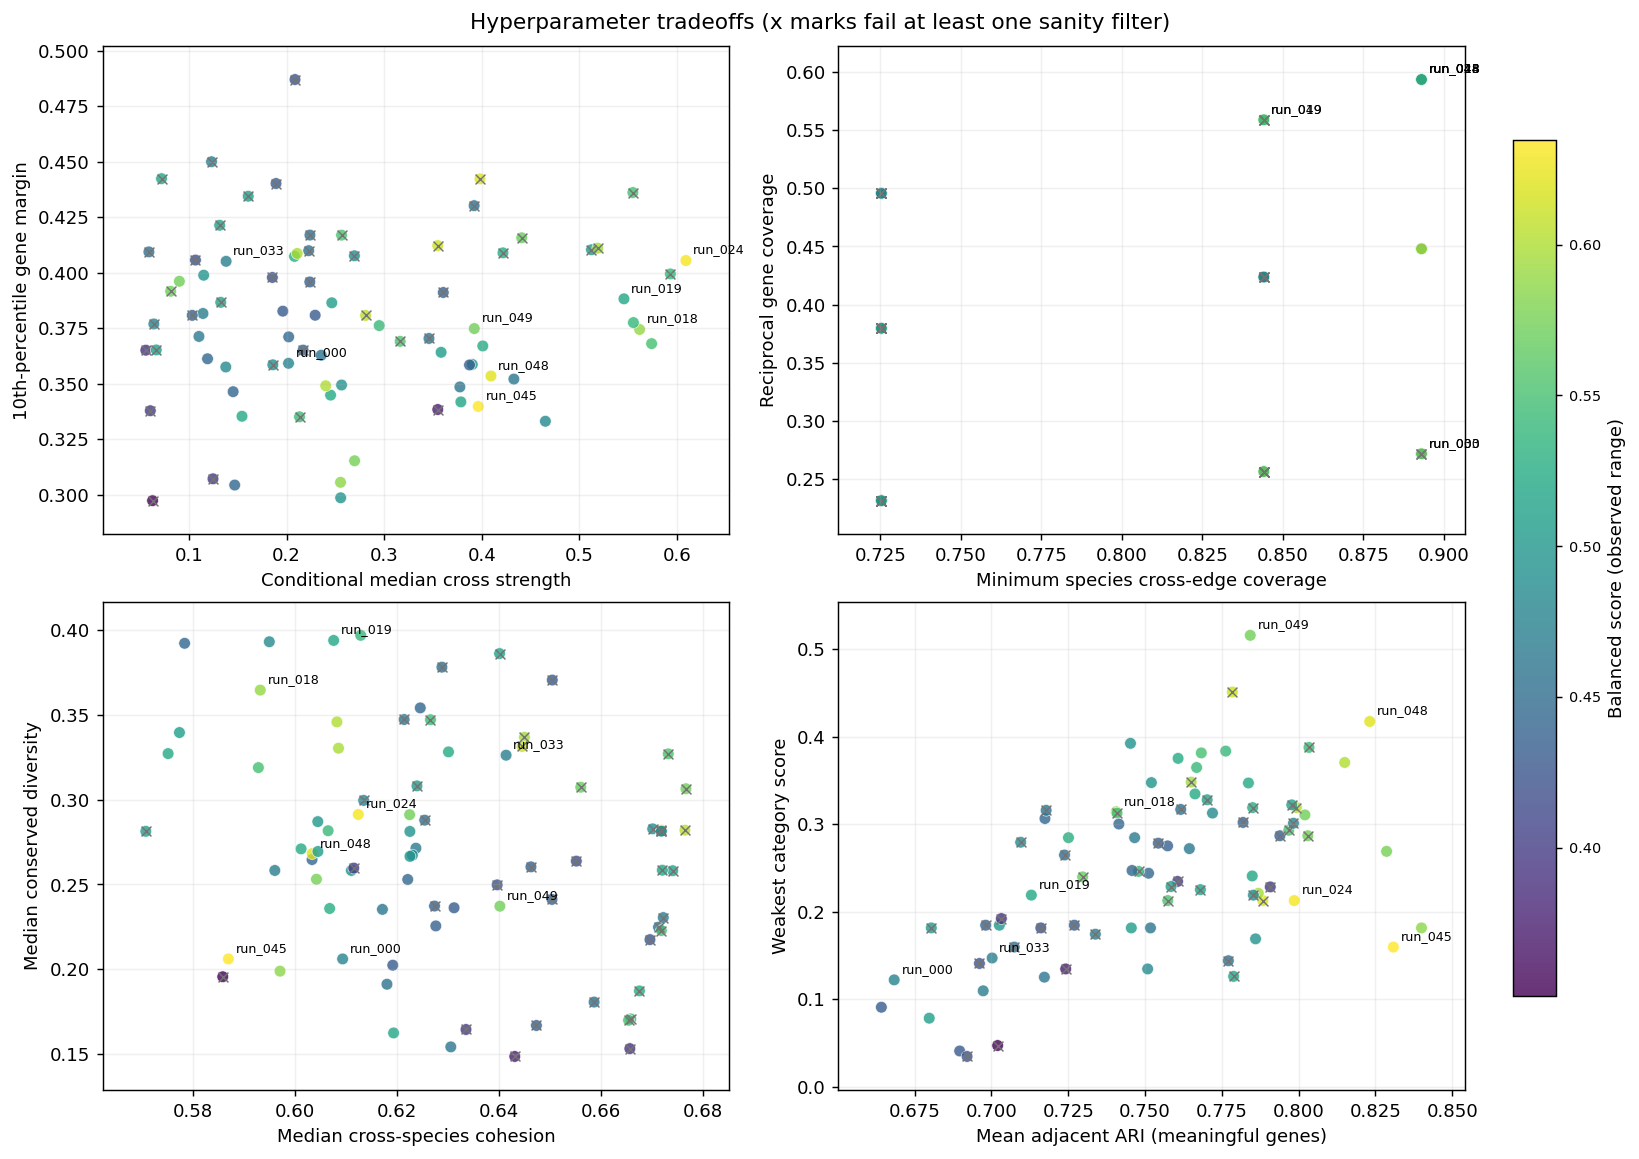

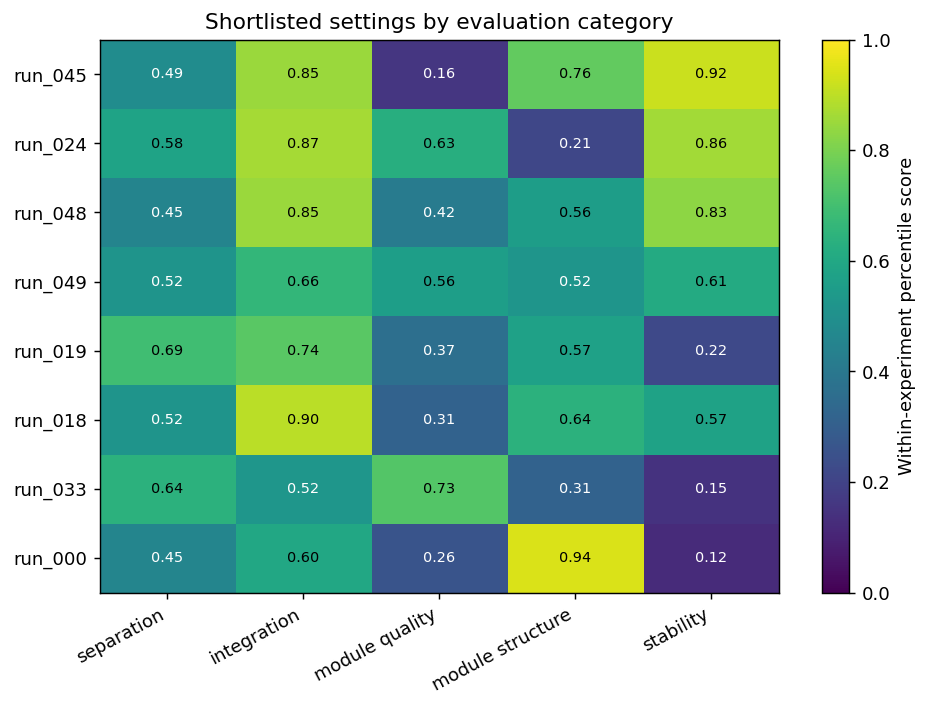

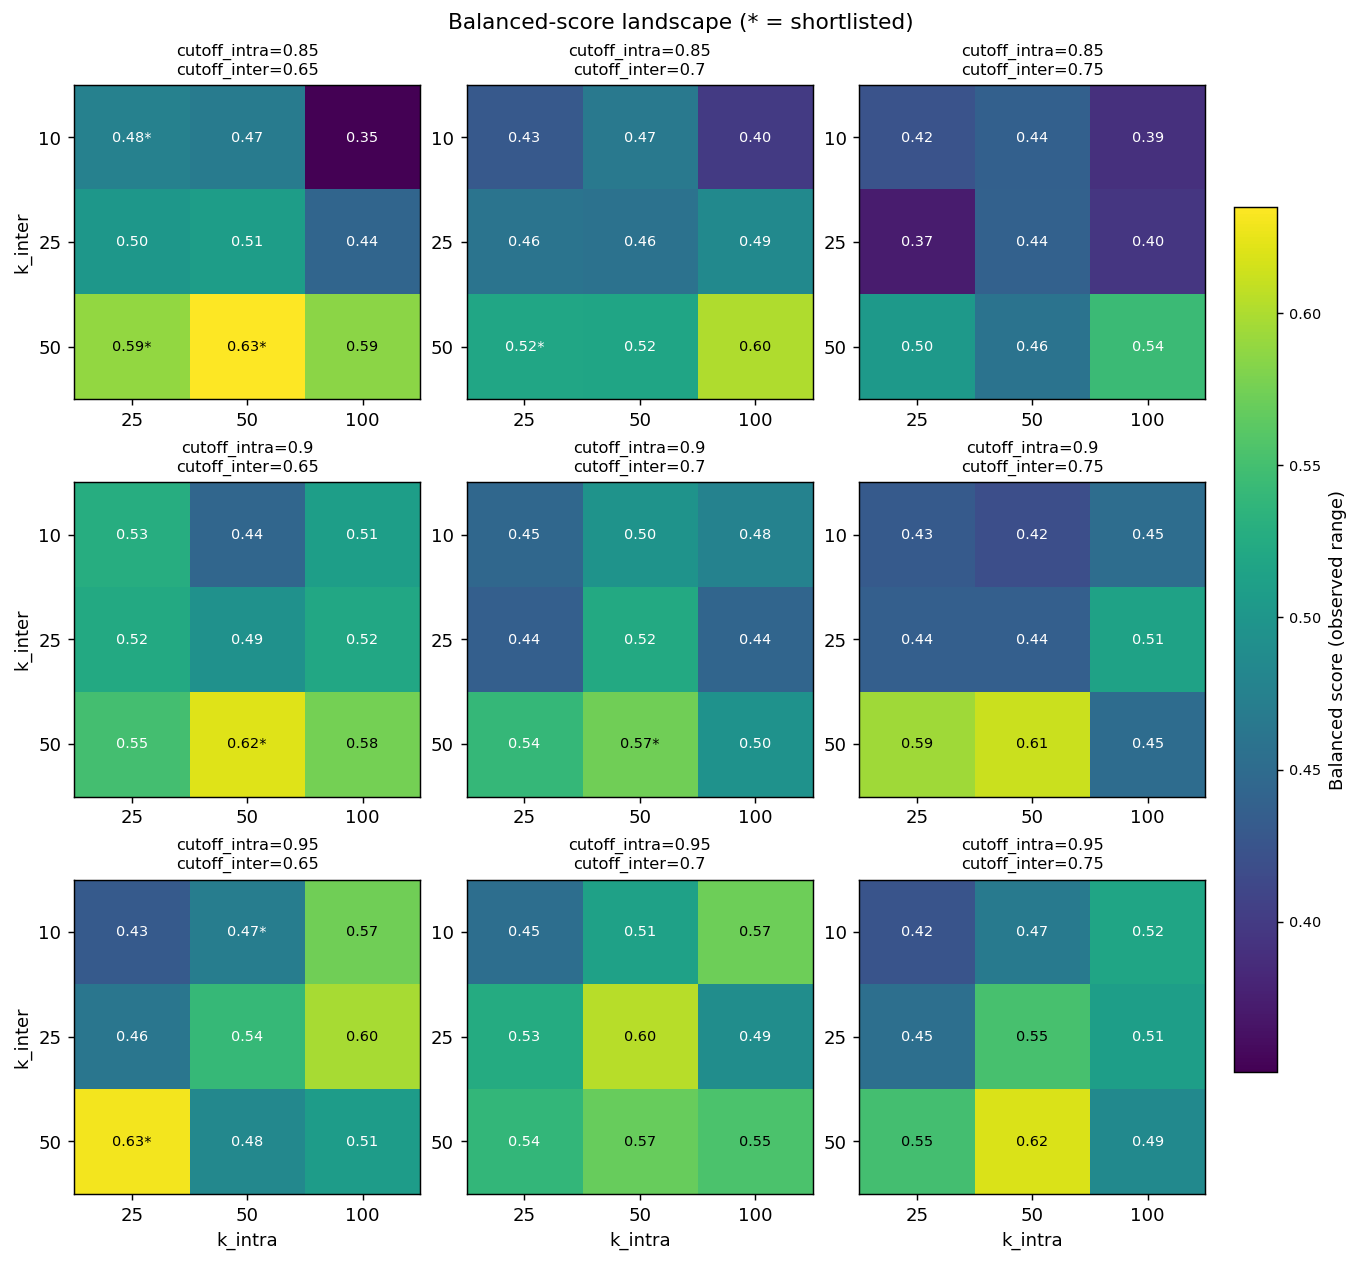

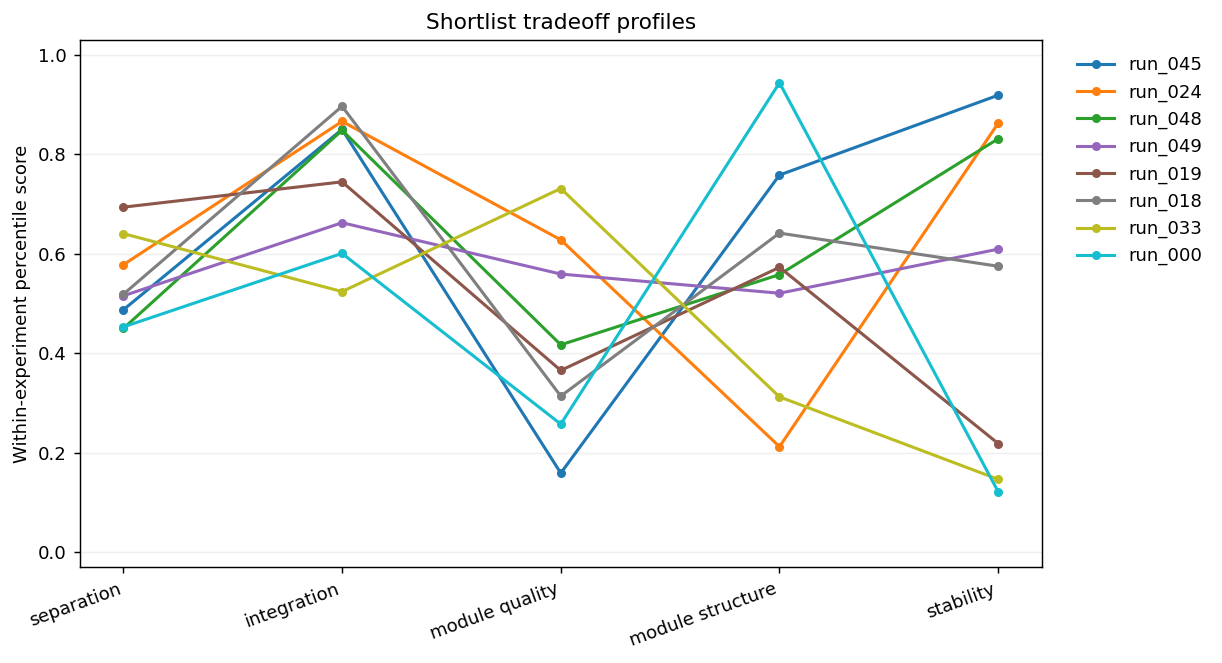

Review written to: hyperparameter_results/module_evaluation_20261009_073527/hyperparameter_review_20261014_205609


,shortlist_rank,name,k_intra,k_inter,cutoff_intra,cutoff_inter,balanced_score,weakest_dimension,separation_score,integration_score,module_quality_score,module_structure_score,stability_score,passes_all_filters,pareto_optimal,selection_reason
0,1,run_045,50,50,0.85,0.65,0.634792,0.159375,0.487500,0.850000,0.159375,0.758333,0.918750,True,True,balanced score
1,2,run_024,25,50,0.95,0.65,0.629464,0.212500,0.578125,0.866071,0.628125,0.212500,0.862500,True,True,balanced score
2,3,run_048,50,50,0.90,0.65,0.620997,0.417188,0.450000,0.848214,0.417188,0.558333,0.831250,True,True,balanced score; strong weakest dimension
3,4,run_049,50,50,0.90,0.70,0.573542,0.515625,0.515625,0.662500,0.559375,0.520833,0.609375,True,True,strong weakest dimension
4,5,run_019,25,50,0.85,0.70,0.519137,0.218750,0.693750,0.744643,0.365625,0.572917,0.218750,True,True,separation
5,6,run_018,25,50,0.85,0.65,0.589182,0.314063,0.518750,0.896429,0.314063,0.641667,0.575000,True,True,integration
6,7,run_033,50,10,0.95,0.65,0.471071,0.146875,0.640625,0.524107,0.731250,0.312500,0.146875,True,True,module quality
7,8,run_000,25,10,0.85,0.65,0.475491,0.121875,0.453125,0.600893,0.257812,0.943750,0.121875,True,True,module structure


In [3]:
RUN_HYPERPARAMETER_REVIEW = True

# Leave this as None to use the newest completed module_evaluation_* directory.
# You can also provide an exact path, for example:
# REVIEW_EXPERIMENT_DIR = "hyperparameter_results/module_evaluation_20261014_120000"
REVIEW_EXPERIMENT_DIR = "hyperparameter_results/module_evaluation_20261009_073527"

if RUN_HYPERPARAMETER_REVIEW:
    hyperparameter_review = review_hyperparameter_experiment(
        REVIEW_EXPERIMENT_DIR,
        min_module_size=10,
        shortlist_size=8,
        show_plots=True,
    )
    print(f"Review written to: {hyperparameter_review['output_dir']}")
    display_columns = [
        "shortlist_rank", "name",
        "k_intra", "k_inter", "cutoff_intra", "cutoff_inter",
        "balanced_score", "weakest_dimension",
        "separation_score", "integration_score",
        "module_quality_score", "module_structure_score", "stability_score",
        "passes_all_filters", "pareto_optimal", "selection_reason",
    ]
    display(hyperparameter_review["shortlist"][display_columns])
else:
    print(
        "Set RUN_HYPERPARAMETER_REVIEW = True after all 27 batches finish. "
        "The newest completed experiment will be selected automatically."
    )
